# E4.02.4 — Fine-tuned Whisper: fill only the missing feature comparisons

**Question:** Is the lower fine-tuned fusion65+32 score associated with PCA compression, adding acoustic features, or their combination?

Use the **Singlish final fusion (Python 3.14)** kernel. This notebook loads the verified cached embeddings and fixed speaker split from the completed E4.02.3 run. It trains only **two missing SVM variants** for the fine-tuned encoder. No Whisper extraction, transcription, encoder training, acoustic extraction, feature ranking, or completed classifier fitting is repeated.

| Representation | SVM dimensions | Action |
|---|---:|---|
| Fine-tuned Whisper full768 | 768 | Import completed predictions |
| Fine-tuned Whisper PCA32 alone | 32 | **New SVM comparison** |
| Acoustic65 + fine-tuned Whisper PCA32 | 97 | Import completed predictions |
| Acoustic65 + fine-tuned Whisper full768 | 833 | **New SVM comparison** |

Focus on the fine-tuned encoder because its observed score fell with fusion. Frozen-small results remain in the completed notebook; no new frozen-small classifiers are fitted here.

Keep the same 27,797 training, 6,084 validation, and 6,119 test clips. Fit preprocessing on training only during C selection; refit on 33,881 development clips after selection. Reuse the 65 acoustic columns selected on training speakers in A1. Both fusion branches are scaled by the inverse square root of their width, following E4.02.3. Full fusion changes both the Whisper width and its branch normalization from the PCA32 version; results concern these complete pipelines.

This is a retrospective diagnostic after viewing earlier test results. Treat additional comparisons as exploratory, not as an independent final model selection. The prior ASR exposure uncertainty and class/source confounding still apply.


In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json
import os

for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '4'

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

working_dir = Path.cwd().resolve()
ROOT = next((p for p in (working_dir, *working_dir.parents)
             if (p / 'notebooks').is_dir() and (p / 'outputs').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the project or notebooks folder.')
NOTEBOOK = ROOT / 'notebooks/E4_02_4_finetuned_feature_ablation.ipynb'
SOURCE = ROOT / 'outputs/e4_02_3_fusion_enabled_40000'
OUT = ROOT / 'outputs/e4_02_4_finetuned_feature_ablation_40000'
E1 = Path('/home/mh/nusproj/E1_Feature_EngineeringV4/outputs/e1_feature_study_accent_40000')

SEED = 42
C_VALUES = [0.01, 0.1, 1.0, 10.0]
BOOTSTRAP_REPEATS = 2000
THREADS = threadpool_limits(limits=4)
FULL = 'Fine-tuned small SVM768'
PCA_ONLY = 'Fine-tuned small PCA32 SVM'
FUSION32 = 'Fine-tuned small fusion65+32'
FUSION768 = 'Fine-tuned small fusion65+768'
REUSED_MODELS = [FULL, FUSION32]
NEW_MODELS = [PCA_ONLY, FUSION768]
NAMES = [FULL, PCA_ONLY, FUSION32, FUSION768]
COMPARISONS = [(PCA_ONLY, FULL), (FUSION32, PCA_ONLY),
               (FUSION768, FULL), (FUSION768, FUSION32)]
PACKAGES = {name: version(name) for name in
            ['numpy', 'scipy', 'pandas', 'scikit-learn', 'joblib', 'matplotlib']}
PRED_COLUMNS = ['clip_id', 'speaker_group', 'source', 'accent_group', 'label',
                'model', 'stage', 'prediction', 'decision_score']

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def write_json(path, value):
    temporary = Path(path).with_name(Path(path).name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + '\n')
    temporary.replace(path)

print('New classifiers:', NEW_MODELS)
print('Imported classifiers:', REUSED_MODELS)
print('Output:', OUT)


New classifiers: ['Fine-tuned small PCA32 SVM', 'Fine-tuned small fusion65+768']
Imported classifiers: ['Fine-tuned small SVM768', 'Fine-tuned small fusion65+32']
Output: /home/mh/nusproj/singlish-whisper/outputs/e4_02_4_finetuned_feature_ablation_40000


In [2]:
def metrics(frame):
    y, p = frame.label.to_numpy(), frame.prediction.to_numpy()
    cm = confusion_matrix(y, p, labels=[0, 1])
    return dict(accuracy=float(accuracy_score(y, p)),
                balanced_accuracy=float(balanced_accuracy_score(y, p)),
                macro_f1=float(f1_score(y, p, average='macro', zero_division=0)),
                roc_auc=float(roc_auc_score(y, frame.decision_score)),
                sg_recall=float(cm[1, 1]/cm[1].sum()), non_sg_fpr=float(cm[0, 1]/cm[0].sum()),
                errors=int(np.sum(y != p)), false_positive=int(cm[0, 1]), false_negative=int(cm[1, 0]),
                confusion_matrix=cm.tolist())

def check_predictions(predictions, expected, name, stage):
    assert len(predictions) == len(expected) and predictions.clip_id.is_unique
    part = predictions.set_index('clip_id').sort_index()
    truth = expected.set_index('clip_id').sort_index()
    pd.testing.assert_frame_equal(part[['speaker_group', 'source', 'accent_group', 'label']],
                                  truth[['speaker_group', 'source', 'accent_group', 'label']],
                                  check_dtype=False)
    assert predictions.model.eq(name).all() and predictions.stage.eq(stage).all()
    assert set(predictions.prediction) <= {0, 1}
    assert np.isfinite(predictions.decision_score).all()

def score_predictions(model, values, expected, name, stage):
    part = expected[['clip_id', 'speaker_group', 'source', 'accent_group', 'label']].copy()
    part['model'], part['stage'] = name, stage
    part['prediction'] = model.predict(values)
    part['decision_score'] = model.decision_function(values)
    part = part[PRED_COLUMNS].reset_index(drop=True)
    check_predictions(part, expected, name, stage)
    return part

def choose_trial(trials):
    return max(trials, key=lambda row: (row['balanced_accuracy'], row['macro_f1'], -row['C']))

def paired_bootstrap(predictions, names, repeats=BOOTSTRAP_REPEATS, seed=SEED):
    # Aggregate confusion counts by speaker. Reuse each draw across all models.
    parts = {name: predictions.loc[predictions.model.eq(name)].set_index('clip_id').sort_index()
             for name in names}
    reference = parts[names[0]][['speaker_group', 'label']]
    assert reference.index.is_unique
    assert reference.groupby('speaker_group').label.nunique().eq(1).all()
    for part in parts.values():
        pd.testing.assert_frame_equal(part[['speaker_group', 'label']], reference)
    speakers = reference.groupby('speaker_group').label.first().sort_index()
    group_positions = speakers.index.get_indexer(reference.speaker_group)
    rng = np.random.default_rng(seed)
    weights = np.zeros((repeats, len(speakers)), dtype=np.int32)
    for label in [0, 1]:
        ids = np.flatnonzero(speakers.eq(label))
        assert len(ids) > 1, 'Each class needs at least two speakers.'
        draws = ids[rng.integers(len(ids), size=(repeats, len(ids)))]
        np.add.at(weights, (np.arange(repeats)[:, None], draws), 1)

    def from_cm(cm):
        tn, fp, fn, tp = np.asarray(cm).T
        return {'balanced_accuracy': .5*(tp/(tp+fn) + tn/(tn+fp)),
                'macro_f1': .5*(2*tp/(2*tp+fp+fn) + 2*tn/(2*tn+fp+fn))}

    samples, scores, rows = {}, {}, []
    for name, part in parts.items():
        cm = np.zeros((len(speakers), 4), dtype=np.int64)
        np.add.at(cm, (group_positions, 2*part.label.to_numpy()+part.prediction.to_numpy()), 1)
        samples[name] = from_cm(weights @ cm)
        result = metrics(part)
        result['speaker_ci95'] = {metric: np.quantile(draws, [.025, .975]).tolist()
                                   for metric, draws in samples[name].items()}
        scores[name] = result
        rows.append(dict(model=name, **{k: v for k, v in result.items()
                                       if k not in ['confusion_matrix', 'speaker_ci95']},
                         ba_ci95_low=result['speaker_ci95']['balanced_accuracy'][0],
                         ba_ci95_high=result['speaker_ci95']['balanced_accuracy'][1],
                         f1_ci95_low=result['speaker_ci95']['macro_f1'][0],
                         f1_ci95_high=result['speaker_ci95']['macro_f1'][1]))
    comparisons = []
    for candidate_name, control in COMPARISONS:
        candidate = parts[candidate_name]
        correct_c = candidate.prediction.eq(candidate.label)
        correct_r = parts[control].prediction.eq(candidate.label)
        for metric in ['balanced_accuracy', 'macro_f1']:
            delta = samples[candidate_name][metric]-samples[control][metric]
            low, high = np.quantile(delta, [.025, .975])
            comparisons.append(dict(candidate=candidate_name, reference=control, metric=metric,
                difference=scores[candidate_name][metric]-scores[control][metric],
                ci95_low=float(low), ci95_high=float(high),
                candidate_only_correct=int((correct_c & ~correct_r).sum()),
                reference_only_correct=int((~correct_c & correct_r).sum())))
    return pd.DataFrame(rows), scores, pd.DataFrame(comparisons)

def source_table(predictions):
    rows = []
    for (name, source), part in predictions.groupby(['model', 'source'], sort=False):
        assert part.label.nunique() == 1, 'Expected one class per source in this dataset.'
        label = int(part.label.iloc[0])
        rows.append(dict(model=name, source=source, label=label, clips=len(part),
                         speakers=part.speaker_group.nunique(),
                         errors=int(part.label.ne(part.prediction).sum()),
                         metric='Singapore recall' if label else 'non-Singapore specificity',
                         value=float(part.label.eq(part.prediction).mean())))
    return pd.DataFrame(rows)

def markdown_table(table):
    # Avoid an optional tabulate dependency.
    clean = table.fillna('').astype(str).map(lambda value: value.replace('|', '/').replace('\n', ' '))
    lines = ['| ' + ' | '.join(map(str, clean.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(clean.columns)) + ' |']
    lines += ['| ' + ' | '.join(row) + ' |' for row in clean.itertuples(index=False, name=None)]
    return '\n'.join(lines)

def describe_difference(row):
    prefix = (f'{row.candidate} minus {row.reference}: {100*row.difference:+.3f} percentage points; '
              f'95% interval [{100*row.ci95_low:+.3f}, {100*row.ci95_high:+.3f}]. ')
    if row.ci95_low > 0:
        return prefix + 'The interval supports a gain on this retrospective test, subject to the ASR exposure audit.'
    if row.ci95_high < 0:
        return prefix + 'The interval supports a lower score on this retrospective test.'
    return prefix + 'A gain is not established. This does not establish equivalence.'


## 1. Reuse and verify the completed data

Verify file hashes before reading cached features and baseline predictions. Load feature arrays read-only. Use the manifest's row order, labels and speaker groups to check the acoustic cache and imported predictions. No raw audio decoding is repeated: the source run already audited all 40,000 clips.


In [3]:
EXPECTED_INPUT_HASHES = {'/home/mh/nusproj/singlish-whisper/outputs/e4_02_3_fusion_enabled_40000/run_record.json': '6b7fbb2ea5b3a74bb09eb00ca17d75b34217f5b5f22039454912ac66dc56758e', '/home/mh/nusproj/singlish-whisper/outputs/e4_02_3_fusion_enabled_40000/finetuned_small_features.npy': 'c5e4e0a84b7f9a8ba470dec1fad3dcf24deb1c641da6299821070f89b3ee0f26', '/home/mh/nusproj/singlish-whisper/outputs/e4_02_3_fusion_enabled_40000/predictions.csv': '509c0554ce8c363c0fee74fecb024ed7ea8490e6f64739645c7992c8164a8459', '/home/mh/nusproj/singlish-whisper/outputs/e4_02_3_fusion_enabled_40000/validation_trials.csv': 'adbf24eca2ca8a584c5c3f840e13082e05639752c2576a616789ef2daa9aa4de', '/home/mh/nusproj/singlish-whisper/outputs/e4_02_3_fusion_enabled_40000/test_scores.csv': '62ac1a0ad2f1230913d57d615449bd88052aca151ebebcfb80501d9107f2213e', '/home/mh/nusproj/E1_Feature_EngineeringV4/outputs/e1_feature_study_accent_40000/speaker_splits.csv': '428937b39eb646a41e46b8ee3cdeb86652069802a675575892e6f17e289b8581', '/home/mh/nusproj/E1_Feature_EngineeringV4/outputs/e1_feature_study_accent_40000/acoustic_features_91.npz': '5bd24a1f3a26b05a02694ed4a1d4e3fc0b72524eaea45d1429276f0f71f2438d'}

for filename, expected in EXPECTED_INPUT_HASHES.items():
    assert sha256(filename) == expected, f'Completed input changed: {filename}'
source_record = json.loads((SOURCE / 'run_record.json').read_text())
assert source_record['status'] == 'complete'
assert source_record['settings']['include_fusion'] is True
assert source_record['dataset']['dataset_id'] == '899dd94a72cff7dc6536993ea0c91ce0aed927a80983050b781c0b71d2f0f4ba'
assert source_record['audio_audit']['status'] == 'passed'
assert source_record['audio_audit']['decoded_hash_matches'] == 40000
assert source_record['settings']['C_values'] == C_VALUES
for package in ['numpy', 'scipy', 'scikit-learn', 'joblib']:
    assert PACKAGES[package] == source_record['packages'][package], package
for filename in ['finetuned_small_features.npy', 'predictions.csv', 'test_scores.csv', 'validation_trials.csv']:
    assert EXPECTED_INPUT_HASHES[str(SOURCE / filename)] == source_record['generated_files'][filename]
assert EXPECTED_INPUT_HASHES[str(E1 / 'speaker_splits.csv')] == source_record['dataset']['original_split_sha256']
assert EXPECTED_INPUT_HASHES[str(E1 / 'acoustic_features_91.npz')] == source_record['input_hashes'][str(E1 / 'acoustic_features_91.npz')]

frame = pd.read_csv(E1 / 'speaker_splits.csv')
assert len(frame) == 40000 and frame.clip_id.is_unique
assert frame.groupby('speaker_group').split.nunique().eq(1).all()
assert frame.groupby('speaker_group').label.nunique().eq(1).all()
split = {stage: np.flatnonzero(frame.split.eq(stage)) for stage in ['train', 'validation', 'test']}
split['development'] = np.sort(np.r_[split['train'], split['validation']])
assert [len(split[k]) for k in ['train', 'validation', 'development', 'test']] == [27797, 6084, 33881, 6119]
for left, right in [('train', 'validation'), ('development', 'test')]:
    assert set(frame.iloc[split[left]].speaker_group).isdisjoint(frame.iloc[split[right]].speaker_group)
train, val, dev, test = [split[k] for k in ['train', 'validation', 'development', 'test']]
y = frame.label.to_numpy()

W = np.load(SOURCE / 'finetuned_small_features.npy', mmap_mode='r', allow_pickle=False)
assert W.shape == (40000, 768) and W.dtype == np.float32 and np.isfinite(W).all()
assert not W.flags.writeable
columns = np.asarray(source_record['selected_columns'], dtype=int)
assert len(columns) == len(set(columns)) == 65
with np.load(E1 / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    for key, expected in [('clip_ids', frame.clip_id), ('labels', frame.label), ('groups', frame.speaker_group)]:
        assert np.array_equal(cache[key], expected), key
    assert cache['features'].shape == (40000, 91)
    acoustic = cache['features'][:, columns].copy()
    acoustic_names = cache['feature_names'][columns].astype(str)
assert np.isfinite(acoustic).all()

imported = pd.read_csv(SOURCE / 'predictions.csv')
baseline_predictions = imported.loc[imported.model.isin(REUSED_MODELS), PRED_COLUMNS].copy()
for stage in ['validation', 'test']:
    for name in REUSED_MODELS:
        part = baseline_predictions.loc[baseline_predictions.stage.eq(stage) & baseline_predictions.model.eq(name)]
        check_predictions(part, frame.iloc[split[stage]], name, stage)
        if stage == 'test':
            observed = metrics(part)
            for key in ['accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc', 'errors', 'false_positive', 'false_negative']:
                assert np.isclose(observed[key], source_record['test_metrics'][name][key], atol=1e-12, rtol=0), (name, key)
baseline_trials = pd.read_csv(SOURCE / 'validation_trials.csv')
baseline_trials = baseline_trials.loc[baseline_trials.model.isin(REUSED_MODELS)].copy()
selected_c = {name: source_record['selected_C'][name] for name in REUSED_MODELS}
for name in REUSED_MODELS:
    rows = baseline_trials.loc[baseline_trials.model.eq(name)]
    assert sorted(rows.C.tolist()) == C_VALUES
    assert choose_trial(rows.to_dict('records'))['C'] == selected_c[name]

inputs = {PCA_ONLY: W, FUSION768: np.column_stack([acoustic, W])}
print('Verified cached rows, fixed speaker splits, and unchanged imported predictions.')
display(pd.DataFrame([dict(partition=k, clips=len(v), speakers=frame.iloc[v].speaker_group.nunique())
                      for k, v in split.items()]))


Verified cached rows, fixed speaker splits, and unchanged imported predictions.


,partition,clips,speakers
0,train,27797,6939
1,validation,6084,1504
2,test,6119,1482
3,development,33881,8443


## 2. Define only the missing pipelines and resume safely

PCA32 alone exactly matches the Whisper branch in fusion65+32: standard scaling → PCA32 → component scaling. Full fusion keeps all 768 Whisper values and the same 65 acoustic columns, scales each branch, and weights branches by 1/√65 and 1/√768 before concatenation. Both use the existing RBF SVM C grid, class weighting, and validation tie break.

Preprocessing is independent of C, so fit it once per representation on training speakers and reuse the transformed arrays across the four C trials. A separate development fit is used after selection. Save each trial and refit; restarting resumes completed work in this new folder.


In [4]:
def make_preprocessor(name):
    if name == PCA_ONLY:
        return Pipeline([('scale', StandardScaler()),
                         ('pca', PCA(n_components=32, random_state=SEED)),
                         ('component_scale', StandardScaler())])
    assert name == FUSION768
    return ColumnTransformer([
        ('acoustic', StandardScaler(), list(range(65))),
        ('whisper', StandardScaler(), list(range(65, 65 + 768)))],
        transformer_weights={'acoustic': 1 / np.sqrt(65), 'whisper': 1 / np.sqrt(768)})

def make_classifier(c):
    return SVC(C=float(c), kernel='rbf', gamma='scale', class_weight='balanced',
               random_state=SEED, cache_size=2048)

def check_preprocessing(preprocessor, name, values):
    if name == PCA_ONLY:
        scalers = [(preprocessor['scale'], values)]
        assert preprocessor['pca'].n_samples_ == len(values)
        assert preprocessor['component_scale'].n_samples_seen_ == len(values)
        assert preprocessor.transform(values[:2]).shape == (2, 32)
    else:
        scalers = [(preprocessor.named_transformers_['acoustic'], values[:, :65]),
                   (preprocessor.named_transformers_['whisper'], values[:, 65:])]
        assert preprocessor.transform(values[:2]).shape == (2, 833)
    for scaler, raw in scalers:
        assert scaler.n_samples_seen_ == len(values)
        np.testing.assert_allclose(scaler.mean_, raw.mean(0, dtype=np.float64), atol=1e-9)

def save_checkpoint(value):
    temporary = OUT / 'study.joblib.tmp'
    joblib.dump(value, temporary, compress=3)
    temporary.replace(OUT / 'study.joblib')

settings = dict(seed=SEED, C_values=C_VALUES, new_models=NEW_MODELS,
                reused_models=REUSED_MODELS, PCA_width=32, full_fusion_width=833,
                branch_weights='1/sqrt(branch width)', bootstrap_repeats=BOOTSTRAP_REPEATS,
                svm='RBF; gamma=scale; class_weight=balanced',
                tie_break='validation BA, macro F1, smaller C', preprocessing_fit='train, then development')
code_sha = hashlib.sha256('\n\n'.join(''.join(c['source']) for c in json.loads(NOTEBOOK.read_text())['cells']
                                     if c['cell_type'] == 'code').encode()).hexdigest()
signature = digest(dict(code_sha=code_sha, settings=settings, packages=PACKAGES, inputs=EXPECTED_INPUT_HASHES))
OUT.mkdir(parents=True, exist_ok=True)
if (OUT / 'study.joblib').exists():
    state = joblib.load(OUT / 'study.joblib')
    assert state['signature'] == signature, 'Code or inputs changed. Use a new OUT folder.'
    print('Resume matching missing-comparison study.')
else:
    assert not any(p.name != 'execution_status.json' for p in OUT.iterdir()), 'Use an empty OUT folder.'
    state = dict(signature=signature, preprocessors={}, trials={}, final={}, selected_C={},
                 started_utc=datetime.now(timezone.utc).isoformat())
    save_checkpoint(state)
record = dict(status='in_progress', signature=signature, code_sha256=code_sha,
              started_utc=state['started_utc'], settings=settings, packages=PACKAGES,
              input_hashes=EXPECTED_INPUT_HASHES, dataset=source_record['dataset'],
              asr_exposure_audit=source_record['asr_exposure_audit'], retrospective=True,
              interpretation='Exploratory feature ablation after inspecting prior test results.',
              new_models=NEW_MODELS, reused_models=REUSED_MODELS,
              selected_columns=columns.tolist(), selected_feature_names=acoustic_names.tolist())
write_json(OUT / 'run_record.json', record)


Resume matching missing-comparison study.


## 3. Select C for the two new variants

The completed full768 and fusion65+32 classifiers are never fitted here. Select each new C using validation balanced accuracy, then macro F1, then smaller C. Test results are not consulted during fitting or selection.


In [5]:
for name in NEW_MODELS:
    unfinished = [c for c in C_VALUES if f'{name}|C={c:g}' not in state['trials']]
    if not unfinished:
        print('All validation trials already complete:', name, flush=True)
        continue
    if name not in state['preprocessors']:
        started = perf_counter()
        preprocessor = make_preprocessor(name).fit(inputs[name][train])
        check_preprocessing(preprocessor, name, inputs[name][train])
        state['preprocessors'][name] = dict(preprocessor=preprocessor, seconds=perf_counter() - started)
        save_checkpoint(state)
    preprocessor = state['preprocessors'][name]['preprocessor']
    transformed_train = preprocessor.transform(inputs[name][train])
    transformed_val = preprocessor.transform(inputs[name][val])
    for c in unfinished:
        key = f'{name}|C={c:g}'
        print('Fit missing trial:', key, flush=True)
        started = perf_counter()
        classifier = make_classifier(c).fit(transformed_train, y[train])
        fit_seconds = perf_counter() - started
        started = perf_counter()
        pred = frame.iloc[val][['clip_id', 'speaker_group', 'source', 'accent_group', 'label']].copy()
        pred['model'], pred['stage'] = name, 'validation'
        pred['prediction'] = classifier.predict(transformed_val)
        pred['decision_score'] = classifier.decision_function(transformed_val)
        pred = pred[PRED_COLUMNS].reset_index(drop=True)
        check_predictions(pred, frame.iloc[val], name, 'validation')
        row = dict(model=name, C=c, fit_seconds=fit_seconds,
                   validation_predict_and_score_seconds=perf_counter() - started,
                   **{k: v for k, v in metrics(pred).items() if k != 'confusion_matrix'},
                   origin='new missing comparison; cached encoder features')
        state['trials'][key] = dict(row=row, predictions=pred)
        save_checkpoint(state)
        print(f'Validation BA: {row["balanced_accuracy"]:.4%}; errors: {row["errors"]}; '
              f'SVM fit: {fit_seconds:.1f}s', flush=True)
    del transformed_train, transformed_val

new_trials = pd.DataFrame([value['row'] for value in state['trials'].values()])
validation_parts = [baseline_predictions.loc[baseline_predictions.stage.eq('validation')]]
for name in NEW_MODELS:
    rows = new_trials.loc[new_trials.model.eq(name)]
    assert sorted(rows.C.tolist()) == C_VALUES
    best = choose_trial(rows.to_dict('records'))
    selected_c[name] = best['C']
    validation_parts.append(state['trials'][f'{name}|C={best["C"]:g}']['predictions'])
state['selected_C'] = selected_c
save_checkpoint(state)
validation_predictions = pd.concat(validation_parts, ignore_index=True)
validation_trials = pd.concat([baseline_trials.assign(origin='imported E4.02.3; not fitted'), new_trials], ignore_index=True)
validation_trials['selected'] = [c == selected_c[name] for name, c in zip(validation_trials.model, validation_trials.C)]
validation_trials.to_csv(OUT / 'validation_trials.csv', index=False)
display(validation_trials[['model', 'C', 'balanced_accuracy', 'errors', 'selected', 'origin']])


All validation trials already complete: Fine-tuned small PCA32 SVM


All validation trials already complete: Fine-tuned small fusion65+768


,model,C,balanced_accuracy,errors,selected,origin
0,Fine-tuned small SVM768,0.01,0.951206,297,False,imported E4.02.3; not fitted
1,Fine-tuned small SVM768,0.10,0.979612,124,False,imported E4.02.3; not fitted
2,Fine-tuned small SVM768,1.00,0.989809,62,False,imported E4.02.3; not fitted
3,Fine-tuned small SVM768,10.00,0.990143,60,True,imported E4.02.3; not fitted
4,Fine-tuned small fusion65+32,0.01,0.969969,183,False,imported E4.02.3; not fitted
5,Fine-tuned small fusion65+32,0.10,0.985554,88,False,imported E4.02.3; not fitted
6,Fine-tuned small fusion65+32,1.00,0.992107,48,True,imported E4.02.3; not fitted
7,Fine-tuned small fusion65+32,10.00,0.991781,50,False,imported E4.02.3; not fitted
8,Fine-tuned small PCA32 SVM,0.01,0.951909,293,False,new missing comparison; cached encoder features
9,Fine-tuned small PCA32 SVM,0.10,0.964503,216,False,new missing comparison; cached encoder features


## 4. Refit only the new variants and keep imported predictions unchanged

Fit selected new pipelines on development speakers, then score the fixed test clips. Keep original predictions byte-for-byte numerically equivalent after CSV loading; imported rows are checked against the saved source metrics.


In [6]:
for name in NEW_MODELS:
    if name in state['final']:
        print('Reuse completed new development fit:', name, flush=True)
        continue
    print('Development refit:', name, '| C =', selected_c[name], flush=True)
    started = perf_counter()
    preprocessor = make_preprocessor(name).fit(inputs[name][dev])
    check_preprocessing(preprocessor, name, inputs[name][dev])
    transformed_dev = preprocessor.transform(inputs[name][dev])
    classifier = make_classifier(selected_c[name]).fit(transformed_dev, y[dev])
    model = Pipeline([('preprocess', preprocessor), ('classifier', classifier)])
    fit_seconds = perf_counter() - started
    del transformed_dev
    started = perf_counter()
    pred = score_predictions(model, inputs[name][test], frame.iloc[test], name, 'test')
    diagnostics = dict(processed_width=32 if name == PCA_ONLY else 833)
    if name == PCA_ONLY:
        diagnostics['development_PCA_variance_retained'] = float(preprocessor['pca'].explained_variance_ratio_.sum())
    state['final'][name] = dict(model=model, predictions=pred, diagnostics=diagnostics,
        timing=dict(model=name, final_fit_seconds=fit_seconds,
                    test_predict_and_score_seconds=perf_counter() - started,
                    origin='new comparison; cached input features'))
    save_checkpoint(state)
    print('New test predictions saved:', name, flush=True)

test_predictions = pd.concat([baseline_predictions.loc[baseline_predictions.stage.eq('test')]] +
                            [state['final'][name]['predictions'] for name in NEW_MODELS], ignore_index=True)
for name in NAMES:
    check_predictions(test_predictions.loc[test_predictions.model.eq(name)], frame.iloc[test], name, 'test')
    check_predictions(validation_predictions.loc[validation_predictions.model.eq(name)], frame.iloc[val], name, 'validation')
for name in REUSED_MODELS:
    actual = test_predictions.loc[test_predictions.model.eq(name)].reset_index(drop=True)
    expected = baseline_predictions.loc[baseline_predictions.stage.eq('test') & baseline_predictions.model.eq(name)].reset_index(drop=True)
    pd.testing.assert_frame_equal(actual, expected)
all_predictions = pd.concat([validation_predictions, test_predictions], ignore_index=True)
assert len(all_predictions) == len(NAMES) * (len(val) + len(test))
all_predictions.to_csv(OUT / 'predictions.csv', index=False)
timing = pd.DataFrame([state['final'][name]['timing'] for name in NEW_MODELS])
display(timing)


Reuse completed new development fit: Fine-tuned small PCA32 SVM


Reuse completed new development fit: Fine-tuned small fusion65+768


,model,final_fit_seconds,test_predict_and_score_seconds,origin
0,Fine-tuned small PCA32 SVM,12.119427,2.746970,new comparison; cached input features
1,Fine-tuned small fusion65+768,65.989264,27.382747,new comparison; cached input features


## 5. Compare four representations; only two were trained here

Use the same 2,000 paired whole-speaker bootstrap draws as the prior analysis. Report balanced accuracy, macro F1, ROC AUC, and both error types. Four exploratory comparisons separate PCA compression, adding acoustics to PCA32, adding acoustics to full768, and replacing compressed Whisper with full Whisper inside fusion. Intervals condition on fitted models and exclude fitting/selection uncertainty; no multiple-comparison correction is applied.

The full768-versus-fusion65+768 comparison also changes RBF geometry through branch weighting. This tests the specified fusion recipe, not feature count in isolation. A gain or decline does not establish a universal causal effect of having more dimensions.


,model,action,processed_features,C,accuracy,balanced_accuracy,macro_f1,roc_auc,false_positive,false_negative,errors
0,Fine-tuned small SVM768,reused E4.02.3,768,10.0,0.993953,0.993951,0.993953,0.999763,18,19,37
1,Fine-tuned small PCA32 SVM,trained here,32,1.0,0.976467,0.976487,0.976466,0.996963,80,64,144
2,Fine-tuned small fusion65+32,reused E4.02.3,97,1.0,0.990521,0.990562,0.990521,0.999614,44,14,58
3,Fine-tuned small fusion65+768,trained here,833,10.0,0.995261,0.995281,0.995260,0.999911,22,7,29


,candidate,reference,metric,difference_pp,low_pp,high_pp
0,Fine-tuned small PCA32 SVM,Fine-tuned small SVM768,balanced_accuracy,-1.746457,-2.486900,-1.112781
1,Fine-tuned small PCA32 SVM,Fine-tuned small SVM768,macro_f1,-1.748685,-2.497664,-1.116799
2,Fine-tuned small fusion65+32,Fine-tuned small PCA32 SVM,balanced_accuracy,1.407463,0.653098,2.266011
3,Fine-tuned small fusion65+32,Fine-tuned small PCA32 SVM,macro_f1,1.405524,0.657264,2.274552
4,Fine-tuned small fusion65+768,Fine-tuned small SVM768,balanced_accuracy,0.132929,-0.122601,0.416652
5,Fine-tuned small fusion65+768,Fine-tuned small SVM768,macro_f1,0.130768,-0.130356,0.416812
6,Fine-tuned small fusion65+768,Fine-tuned small fusion65+32,balanced_accuracy,0.471923,0.233249,0.736223
7,Fine-tuned small fusion65+768,Fine-tuned small fusion65+32,macro_f1,0.473928,0.233801,0.761280


Fine-tuned small PCA32 SVM minus Fine-tuned small SVM768: -1.746 percentage points; 95% interval [-2.487, -1.113]. The interval supports a lower score on this retrospective test.
Fine-tuned small fusion65+32 minus Fine-tuned small PCA32 SVM: +1.407 percentage points; 95% interval [+0.653, +2.266]. The interval supports a gain on this retrospective test, subject to the ASR exposure audit.
Fine-tuned small fusion65+768 minus Fine-tuned small SVM768: +0.133 percentage points; 95% interval [-0.123, +0.417]. A gain is not established. This does not establish equivalence.
Fine-tuned small fusion65+768 minus Fine-tuned small fusion65+32: +0.472 percentage points; 95% interval [+0.233, +0.736]. The interval supports a gain on this retrospective test, subject to the ASR exposure audit.


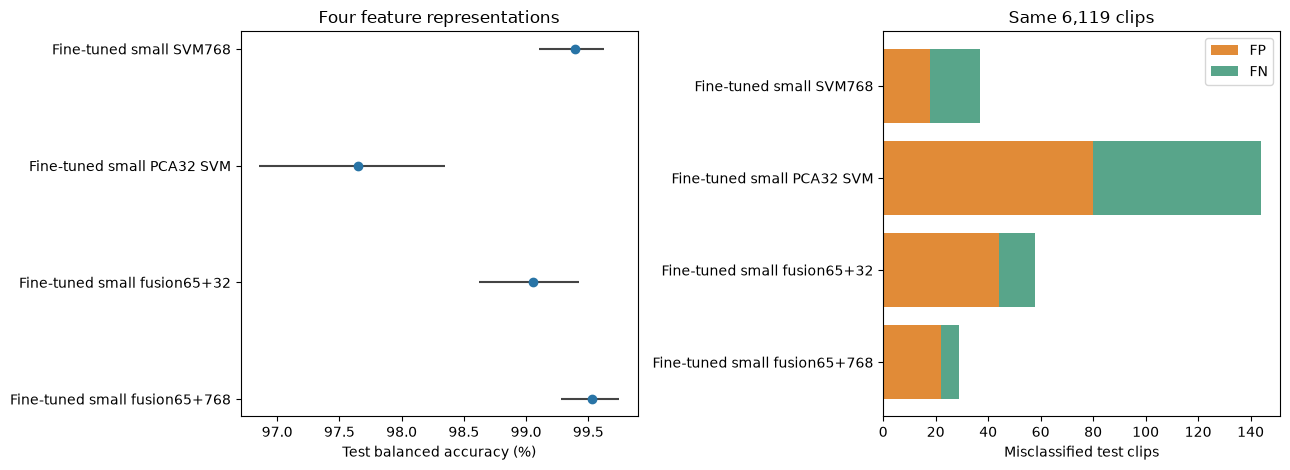

In [7]:
test_scores, score_details, paired = paired_bootstrap(test_predictions, NAMES)
test_scores['C'] = test_scores.model.map(selected_c)
test_scores['processed_features'] = test_scores.model.map({FULL: 768, PCA_ONLY: 32, FUSION32: 97, FUSION768: 833})
test_scores['action'] = test_scores.model.map({name: 'reused E4.02.3' for name in REUSED_MODELS} |
                                            {name: 'trained here' for name in NEW_MODELS})
test_scores.to_csv(OUT / 'test_scores.csv', index=False)
paired.to_csv(OUT / 'paired_differences.csv', index=False)
subgroups = source_table(test_predictions)
subgroups.to_csv(OUT / 'source_scores.csv', index=False)
display(test_scores[['model', 'action', 'processed_features', 'C', 'accuracy', 'balanced_accuracy',
                     'macro_f1', 'roc_auc', 'false_positive', 'false_negative', 'errors']])
paired_display = paired.assign(difference_pp=100 * paired.difference,
                               low_pp=100 * paired.ci95_low, high_pp=100 * paired.ci95_high)
display(paired_display[['candidate', 'reference', 'metric', 'difference_pp', 'low_pp', 'high_pp']])
ba_pairs = paired.loc[paired.metric.eq('balanced_accuracy')].reset_index(drop=True)
for row in ba_pairs.itertuples(index=False):
    print(describe_difference(row))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(NAMES))
axes[0].hlines(x, 100 * test_scores.ba_ci95_low, 100 * test_scores.ba_ci95_high, color='#444444')
axes[0].scatter(100 * test_scores.balanced_accuracy, x, color='#2874a6', zorder=3)
axes[0].set(yticks=x, yticklabels=NAMES, xlabel='Test balanced accuracy (%)', title='Four feature representations')
axes[0].invert_yaxis()
axes[1].barh(x, test_scores.false_positive, label='FP', color='#e18b37')
axes[1].barh(x, test_scores.false_negative, left=test_scores.false_positive, label='FN', color='#58a58a')
axes[1].set(yticks=x, yticklabels=NAMES, xlabel='Misclassified test clips', title='Same 6,119 clips')
axes[1].invert_yaxis()
axes[1].legend()
fig.tight_layout()
plt.show()
plt.close(fig)


## 6. Save the diagnostic result

Save predictions, fitted new pipelines and trial progress, metrics, paired intervals, and a short report in the new E4.02.4 folder. No existing notebook or source result is changed. The report preserves the unresolved ASR exposure status and the retrospective nature of the analysis. It does not automatically replace any current app model.


In [8]:
for filename, expected in EXPECTED_INPUT_HASHES.items():
    assert sha256(filename) == expected, f'Source input changed during execution: {filename}'
conclusions = [describe_difference(row) for row in ba_pairs.itertuples(index=False)]
table = test_scores[['model', 'action', 'processed_features', 'accuracy', 'balanced_accuracy',
                     'macro_f1', 'false_positive', 'false_negative', 'errors']].copy()
for column in ['accuracy', 'balanced_accuracy']:
    table[column] = table[column].map(lambda value: f'{100 * value:.3f}%')
lines = [
    '# E4.02.4: fine-tuned Whisper feature ablation', '',
    'Status: complete. Only PCA32-alone and acoustic65+full768 classifiers were fitted here.', '',
    'The full768 and acoustic65+PCA32 predictions, C selections, and scores were imported unchanged from E4.02.3. '
    'Cached encoder features and the training-selected acoustic65 columns were reused. No audio or encoder extraction was repeated.', '',
    '## Test results', '', markdown_table(table), '',
    '## Paired balanced-accuracy comparisons', '', *conclusions, '',
    '## Interpretation limits', '',
    'Exploratory retrospective ablation after inspecting earlier test results. The test set did not select C. '
    'The 2,000 paired whole-speaker bootstrap intervals condition on fitted models and exclude training/selection uncertainty. '
    'No multiple-comparison correction. Full fusion changes PCA compression and Whisper branch scaling; feature count alone is not isolated.', '',
    'ASR exposure audit: ' + source_record['asr_exposure_audit']['status'] + '.', '',
    'All Singapore positives come from MNSC, so source and accent remain confounded. '
    'No independent speaker-held-out gain can be claimed until all ASR training and checkpoint-selection exposure is checked.', '',
    '## New validation trials', '', markdown_table(new_trials[['model', 'C', 'balanced_accuracy', 'macro_f1', 'errors']]), '',
    '## Source diagnostics', '', markdown_table(subgroups), '',
    '## New fitting time', '', markdown_table(timing), '',
    'Source: ' + str(SOURCE) + '. All source input hashes were rechecked after execution.', '',
]
(OUT / 'report.md').write_text('\n'.join(lines) + '\n')
record.update(status='complete', completed_utc=datetime.now(timezone.utc).isoformat(),
              selected_C=selected_c, test_metrics=score_details,
              paired_differences=paired.to_dict('records'), source_scores=subgroups.to_dict('records'),
              diagnostics={name: state['final'][name]['diagnostics'] for name in NEW_MODELS},
              timing=timing.to_dict('records'), test_clips=len(test),
              test_speakers=frame.iloc[test].speaker_group.nunique(),
              new_trial_count=len(state['trials']), new_final_fit_count=len(state['final']),
              reused_predictions_unchanged=True, source_inputs_unchanged=True)
assert set(state['final']) == set(NEW_MODELS)
assert len(state['trials']) == len(NEW_MODELS) * len(C_VALUES)
record['generated_files'] = {p.name: sha256(p) for p in OUT.iterdir()
                             if p.is_file() and p.name not in ['run_record.json', 'execution_status.json']}
write_json(OUT / 'run_record.json', record)
display(Markdown('**Only the two missing comparisons are complete.** Report: `' + str(OUT / 'report.md') + '`'))


**Only the two missing comparisons are complete.** Report: `/home/mh/nusproj/singlish-whisper/outputs/e4_02_4_finetuned_feature_ablation_40000/report.md`